In [1]:
import numpy as np
import matplotlib.pyplot as plt
import all_functions as funcs
import os
import pickle
import scipy.io

In [2]:
results_path=os.getcwd()+"/Results/"
if not os.path.exists(results_path):
    os.makedirs(results_path)
else:
    print(f"Folder already exists")

Folder already exists


In [3]:
def run_sim(network_params, simulation_params):
    setups = simulation_params["setups"]
    batch = simulation_params["batch"]
    v = simulation_params["v"]
    d = simulation_params["d"]
    norm_type = simulation_params["norm_type"]
    seed = simulation_params["seed"]

    K = network_params["K"]
    SINR = np.zeros((K,setups))

    np.random.seed(seed)
    p_max=network_params["p_k"]

    # A network setup is generated, distances and spatial correlation matrices are calculated
    R_spatial_corr_norm, B_channel_gain, HMean_norm, k_rician_factor, UEpos, APpos = funcs.simulation_area(network_params)

    # Cooperation clusters formation and pilot assignment
    D_cellular, D_DCC, pilot_indicies = funcs.initial_access(network_params,B_channel_gain)

    # for same network setup , k-factor for all channels is set equal to 0 and in next iteration to 5 to cover both cases.
    k_rician_factor[:]=d

    # Generate random channels, channel mean(los component) and spatial correlation matrix
    H, HMean, R_spatial_corr = funcs.channel_generation(network_params, R_spatial_corr_norm,HMean_norm,k_rician_factor)

    # Estimate channels using MMSE estimator  (CSI is obtained)
    H_hat = funcs.channel_estimation(network_params, R_spatial_corr, pilot_indicies, H,
                                                        HMean, p_max)

    #reshaping
    H = np.moveaxis(H, -1, 0)
    H_hat = np.moveaxis(H_hat, -1, 0)
    H = np.swapaxes(H, 2, 3)
    H_hat = np.swapaxes(H_hat, 2, 3)
    K=network_params["K"]

    M, u, b, C, sigma = funcs.calculate_interf_matrix(network_params, D_DCC, H_hat, H)

    for i in range(setups):
        p_inital = np.random.uniform(low=np.nextafter(0,1), high=np.nextafter(1,2), size=(K,1))     #draw random initial power for each user ]0,1]
        p_k = p_max / np.linalg.norm(p_inital, norm_type) * p_inital   # Kx1 power vector for all UEs (scaled such that power constraint fulfilled with equality)

        # SINR[:,i][:,np.newaxis]= funcs.compute_SINR_MRC(network_params, p_k, D_DCC, H_hat, H)
        SINR[:,i][:,np.newaxis] = funcs.sinr(M,u,p_k)
        # print("Progress: ", i, "/",setups)

    return M, u, b, C, sigma, SINR, UEpos, APpos, D_DCC

In [4]:
network_params = {"realizations": 200  #(200 originally) small scale realizations  (Critical : should be a large value if large number APs and UEs are used)
                    , "delta_h": 10 # height difference
                    , "area": 100  # lxl Service Area
                    , "bandwidth": 100e6
                    , "L": 10  # APs
                    , "N": 2  # antennas per AP
                    , "K": 8  # UEs
                    , "tau_c": 200 # total samples in coherence block
                    , "tau_p": 40  # samples for pilots
                    , "p_k": 200  # uplink max power (mW)
                    , "uplink_variance_dbm": -94 # Receiver noise power (dBm)
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 4  # Shadow fading LoS (dB)
                                     }

In [5]:
simulation_params = {"setups": 1000,
                     "batch":network_params["realizations"],
                     "v":-1,
                     "d": 0,   #rician factor (0: no LoS component)
                     "norm_type" : np.inf,
                     "seed": 11
                    }

In [6]:
M, u, b, C, sigma, SINR, UEpos, APpos, D_DCC = run_sim(network_params, simulation_params)

In [7]:
# %matplotlib inline

# x,y,z = SINR
# rate_x = np.log2(1+np.array(x) )
# rate_y = np.log2(1+np.array(y) )
# rate_z = np.log2(1+np.array(z) )

# # Create a figure with two 3D subplots
# fig, (ax1, ax2) = plt.subplots(1, 2, subplot_kw={'projection': '3d'}, figsize=(14,6))
# # fig = plt.figure()
# # ax = fig.add_subplot(projection='3d')
# ax1.scatter(x,y,z)

# ax1.set_xlabel("SINR - User 1", fontsize=10)
# ax1.set_ylabel("SINR - User 2", fontsize=10)
# ax1.set_zlabel("SINR - User 3", fontsize=10)
# ax1.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°

# ax2.scatter(rate_x, rate_y, rate_z)

# ax2.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=10)
# ax2.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=10)
# ax2.set_zlabel("Rate [bit/s/Hz] - User 3", fontsize=10)
# ax2.view_init(elev=30, azim=45)  # Set elevation to 30° and azimuth to 45°

# plt.tight_layout()
# plt.show()

User 0 Serving APs: [0 9]
User 1 Serving APs: [0 1]
User 2 Serving APs: [6 7]
User 3 Serving APs: [5 8]
User 4 Serving APs: [1 6]
User 5 Serving APs: [6 7]
User 6 Serving APs: [6 9]
User 7 Serving APs: [2 4]


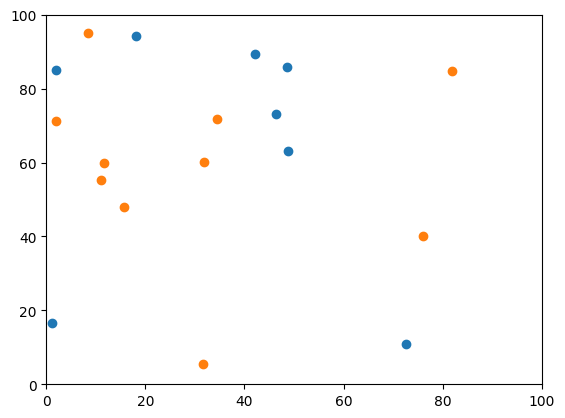

In [8]:
K = network_params["K"]

area = network_params["area"]
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(np.real(UEpos), np.imag(UEpos))
ax.scatter(np.real(APpos), np.imag(APpos))
ax.set_xlim(0, area)
ax.set_ylim(0, area)

# print(D_DCC)
for k in range(K):
    servingAP = np.asarray(np.where(D_DCC[:, k] == 1)).reshape(-1)
    print("User",k,"Serving APs:", servingAP)

In [9]:
p_max=network_params["p_k"]
K = network_params["K"]

A = 1/p_max * np.eye(K)
M_k = np.zeros((K,K,K))
for k in range(K):
    M_k[k,:,:] = M + u @ A[:,k][:,np.newaxis].T
    M_k_inv = np.linalg.inv(M_k[k,:,:])
    # print("M_",k,": ",M_k[k,:,:],"\n")
    # print("Inv: ", M_k_inv,"\n")
    print("Z-matrix? ", funcs.is_ZMatrix(M_k_inv),"\n")


Z-matrix?  False 

Z-matrix?  False 

Z-matrix?  False 

Z-matrix?  False 

Z-matrix?  False 

Z-matrix?  False 

Z-matrix?  False 

Z-matrix?  False 

